In [1]:
## GENERAMOS UNA LISTA DE n PUNTOS QUE LLAMAMOS CITIES
## PARA NO DESVIARNOS DEL PROBLEMA ORIGINAL (los puntos son ciudades)
n = 10
cities = [vector((random(), random())) for _ in range(n + 1)]

## CALCULAMOS LAS DISTANCIAS RECUERDE dii = INF
d = zero_matrix(RR, n + 1, n + 1)
for i in range(n+1):
    for j in range(n+1):
        d[i,j] = norm(cities[j] - cities[i])
        if i == j:
            d[i,j] = 1e5

In [2]:
## PROBLEM STATEMENT USING THE MODEL IN Integer Programming by Harold Greensberg
TSP = MixedIntegerLinearProgram(maximization = False)
x = TSP.new_variable(binary = True,nonnegative=True)
u = TSP.new_variable(nonnegative=True)
TSP.set_objective(sum([d[i,j]*x[i,j] for i in range(n+1) for j in range(n+1)]))

## LAS CONDICIONES SOBRE LAS COLUMNAS
for j in range(n + 1):
    TSP.add_constraint(sum([x[i,j] for i in range(n + 1)]) == 1)
## AHORA SOBRE LAS FILAS
for i in range(1,n + 1):
    TSP.add_constraint(sum([x[i,j] for j in range(n + 1)]) == 1)
## LAS RESTRICCIONES TURBADAS
for i in range(1,n + 1):
    for j in range(1,n + 1):
        TSP.add_constraint(u[i] - u[j] + n*x[i,j],max = n - 1)

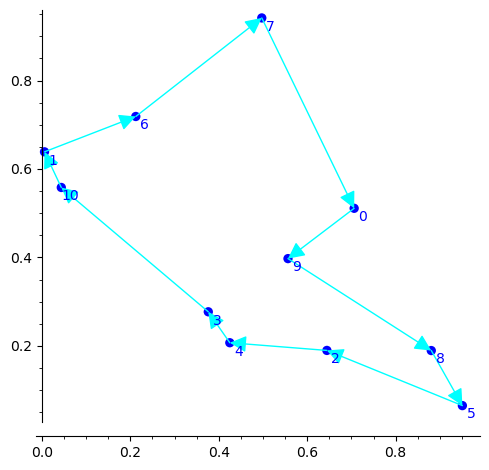

In [3]:
#RESOLVEMOS EL PROBLEMA Y ORDENAMOS LA SOLUCIONES
TSP.solve()
solx = TSP.get_values(x)
solu = TSP.get_values(u)
for i in range(n+1):
    cad = ''
    for j in range(n+1):
        cad += '%d  '%round(solx[i,j])
    #print cad
    
#GRAFICAMOS LA SOLUCION
figu = point2d(cities,size=45)
dezp = 0.02*vector([1,-1])

for i in solx.keys():
    if solx[i]:
        origen = cities[i[0]]
        destin = cities[i[1]]
        figu += arrow2d(origen,destin,color='cyan',width=1)
    
for p in range(len(cities)):
    figu += text('%s'%(p) , vector(cities[p])+dezp)
    
figu.show(aspect_ratio=1)

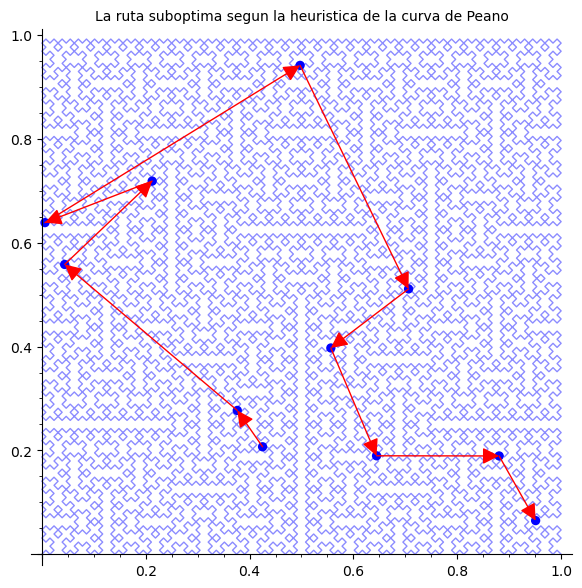

In [5]:
def dist(p1,p2):
    ''' ACCESORIO PARA ENCONTRAR LA DISTANCIAS '''
    return sqrt((p1[0]-p2[0])^2 + (p1[1]-p2[1])^2)

def peano2(n):
    ''' RECURSIVE FUNCTION IS A COMMON ALGORITHM TO PRODUCE THESE KIND OF CURVES '''
    if n <= 1:
        return [[0,1/2,1],[0,1/2,0]]
    else:
        [C,D] = peano2(n-1)
        C1=[[],[],[],[]]
        D1=[[],[],[],[]]
        for i in range(len(C)):
            C1[0].insert(0,1/2*D[i])
            C1[1].append(1/2*C[i])
            C1[2].append(1/2*(C[i]+1))
            C1[3].insert(0,1/2*(2-D[i]))
            D1[0].insert(0,1/2*(1-C[i]))
            D1[1].append(1/2*(D[i]+1))
            D1[2].append(1/2*(D[i]+1))
            D1[3].insert(0,1/2*C[i])
        return [C1[0]+C1[1]+C1[2]+C1[3],D1[0]+D1[1]+D1[2]+D1[3]]

k = 7 ## ORDEN DE LA CURVA DE PEANO A GENERARSE
lis = peano2(k)
L = list(zip(lis[0],lis[1]))
cities_indexed = []
for c in cities:
    for ind,pair in enumerate(L):
        if dist(pair,c) <= 1/2^(k-1):
            cities_indexed.append((c,ind))
            break

#DEFINIMOS LA FUNCION PARA ORDENAR LAS CIUDADES (CON LAS MANECILLAS DEL RELOJ)
cities_sort = sorted(cities_indexed, key=lambda k:k[1])
len(cities_sort)


#THE SUBOPTIMAL ROUTE ACCORDING TO THE PEANO HEURISTIC
graf = list_plot(L,plotjoined=True,alpha=0.45)
graf += point2d(cities,size=45)
for i in range(1,len(cities_sort)):
    origen = cities_sort[i-1][0]
    destin = cities_sort[i][0]
    graf += arrow2d(origen,destin,color='red',width=1)
graf.show(figsize=8,aspect_ratio=1,title='La ruta suboptima segun la heuristica de la curva de Peano')

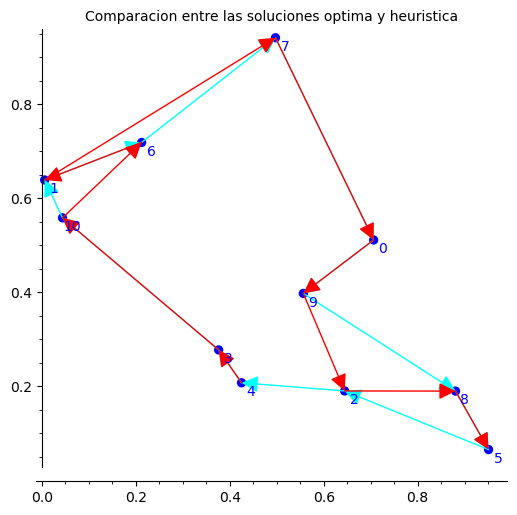

In [7]:
figu = point2d(cities,size=45)
dezp = 0.02*vector([1,-1])

for i in solx.keys():
    if solx[i]:
        origen = cities[i[0]]
        destin = cities[i[1]]
        figu += arrow2d(origen,destin,color='cyan',width=1)
    
for p in range(len(cities)):
    figu += text('%s'%(p) , vector(cities[p])+dezp)
    
for i in range(1,len(cities_sort)):
    origen = cities_sort[i-1][0]
    destin = cities_sort[i][0]
    figu += arrow2d(origen,destin,color='red',width=1)


figu.show(figsize=7,aspect_ratio=1,title='Comparacion entre las soluciones optima y heuristica')